# Instituto Superior de Engenharia do Porto (ISEP)
## Departamento de Engenharia Electrotécnica (DEE)
### Unidade Curricular: Sinais e Sistemas (SINSI) — Ano Letivo 2026/2027

---
# Resolução da Folha Prática TP05b
## Transformada de Laplace Unilateral, Circuitos RLC com Condições Iniciais (ZIR/ZSR) e Regras Universais de Estabilidade e Causalidade via Diagrama Zero-Polar

**Docente:** Prof. Luís Pinto-Coelho  
**Área Científica:** Engenharia Electrotécnica e de Computadores / Automação e Sistemas  

---

### Objetivos Pedagógicos e Competências a Desenvolver:
1. **Dominar a Transformada de Laplace Unilateral ($\mathcal{L}_+$)** como a ferramenta matemática canónica para a análise de sistemas dinâmicos causais sujeitos a condições iniciais não nulas ($t = 0^-$), compreendendo o significado físico do instante $0^-$ na preservação da continuidade das variáveis de estado (carga/tensão no condensador e fluxo/corrente na bobina).
2. **Compreender o Significado Formal de EDLCC** (Equação Diferencial Linear de Coeficientes Constantes) e a sua relação direta com as propriedades de linearidade e invariância no tempo (LIT) de circuitos elétricos.
3. **Modelar Circuitos Elétricos Dinâmicos no Domínio de Laplace**, formulando equações a partir das Leis de Kirchhoff tanto no domínio do tempo como diretamente por impedâncias operacionais no domínio-$s$, obtendo funções de transferência $H(s)$ em regime de repouso.
4. **Decompor a Resposta Completa de Sistemas LIT**:
   - *Decomposição Causal*: Resposta de Entrada Nula (**ZIR** — *Zero-Input Response* / Modo Natural) e Resposta de Estado Nulo (**ZSR** — *Zero-State Response* / Modo Forçado).
   - *Decomposição Temporal*: Resposta **Transitória** ($y_{\text{tr}}(t) \to 0$) e Resposta em **Regime Permanente** ($y_{\text{rp}}(t)$).
5. **Estabelecer Regras Universais de Avaliação de Causalidade e Estabilidade BIBO a partir do Diagrama Zero-Polar**, compreendendo geometricamente como as partes reais dos pólos particionam o plano complexo $s$ em múltiplas Regiões de Convergência (ROCs) possíveis e deduzindo as respostas impulsionais temporais correspondentes.
6. **Implementar e Validar Simulações Computacionais em Python**, recorrendo às bibliotecas `SymPy` (computação analítica e frações parciais), `SciPy.signal` (simulação dinâmica e resposta temporal) e `Matplotlib` (visualização profissional no plano complexo e respostas transitórias).


## 1. Enquadramento Teórico Complementar

> **Nota Pedagógica Prévia do Docente:**  
> No caderno anterior (*TP05a_Resolucao.ipynb*), estabelecemos as bases formais da Transformada de Laplace Bilateral, a definição axiomática de Região de Convergência (ROC), a técnica de inversão por frações simples e a análise de sistemas lineares em repouso com condições iniciais nulas.  
> No presente documento, cobrimos **exclusivamente os tópicos teóricos avançados não contemplados na TP05a**: a **Transformada de Laplace Unilateral ($\mathcal{L}_+$)** para tratamento de sistemas com condições iniciais não nulas ($t = 0^-$), a definição formal de **EDLCC**, a **decomposição canónica ZIR/ZSR**, a **modelação operacional direta por impedâncias**, e as **regras completas de causalidade e estabilidade BIBO a partir de um diagrama zero-polar genérico**.

---

### 1.1. Da Transformada Bilateral à Transformada de Laplace Unilateral ($\mathcal{L}_+$)

Enquanto a Transformada Bilateral opera no horizonte temporal completo ($-\infty < t < +\infty$) e é vocacionada para a análise teórica de sinais e estabilidade de sistemas genéricos, a grande maioria dos problemas práticos de Engenharia Electrotécnica envolve sistemas **causais excitados a partir de um instante de referência** (habitualmente $t = 0$), possuindo energia previamente armazenada nos seus elementos reactivos.

A **Transformada de Laplace Unilateral** define-se formalmente por:
$$\boxed{\mathcal{X}_u(s) = \mathcal{L}_+\{x(t)\} = \int_{0^-}^{+\infty} x(t) e^{-st} \, dt}$$

#### Porquê o limite inferior $0^-$ (*zero-menos*) e não $0^+$?
Em circuitos elétricos com manobras de interruptores e sinais com descontinuidades (como o degrau unitário $u(t)$ ou impulsos $\delta(t)$):
1. O limite $0^- = \lim_{\epsilon \to 0^+} (0 - \epsilon)$ garante a inclusão integral de impulsos de Dirac $\delta(t)$ que ocorram exatamente na origem $t = 0$.
2. As variáveis de estado do circuito — a **corrente no indutor $i_L(t)$** (associada ao fluxo magnético $\lambda = L i_L$) e a **tensão no condensador $v_C(t)$** (associada à carga electrostática $q = C v_C$) — não podem sofrer descontinuidades na presença de tensões e correntes finitas (princípio da conservação de energia):
   $$i_L(0^+) = i_L(0^-), \quad v_C(0^+) = v_C(0^-)$$
   Avaliar as condições iniciais em $t = 0^-$ permite utilizar o estado de carga acumulado no passado histórico ($t < 0$) sem contaminações provocadas pelas descontinuidades das fontes ligadas no instante $t=0$.

#### Propriedade Fundamental da Diferenciação no Tempo com Condições Iniciais:
Integrando por partes a definição da transformada unilateral para a derivada primeira:
$$\mathcal{L}_+\left\{ \frac{dx(t)}{dt} \right\} = \int_{0^-}^{+\infty} \frac{dx(t)}{dt} e^{-st} \, dt = \left[ x(t) e^{-st} \right]_{0^-}^{+\infty} + s \int_{0^-}^{+\infty} x(t) e^{-st} \, dt$$
Assumindo que $s$ se encontra na ROC tal que $\lim_{t \to +\infty} x(t) e^{-st} = 0$:
$$\boxed{\mathcal{L}_+\left\{ \frac{dx(t)}{dt} \right\} = s X(s) - x(0^-)}$$

Por indução matemática, para a segunda derivada:
$$\boxed{\mathcal{L}_+\left\{ \frac{d^2 x(t)}{dt^2} \right\} = s^2 X(s) - s x(0^-) - x'(0^-)}$$
onde $x'(0^-) = \left. \frac{dx(t)}{dt} \right|_{t=0^-}$.  
Para uma derivada de ordem $n$ qualquer:
$$\boxed{\mathcal{L}_+\left\{ \frac{d^n x(t)}{dt^n} \right\} = s^n X(s) - \sum_{k=1}^n s^{n-k} x^{(k-1)}(0^-)}$$

#### Propriedade da Integração no Tempo com Condições Iniciais:
Considerando o acumulador causal de sinal $y(t) = \int_{-\infty}^t x(\tau) \, d\tau$:
$$y(t) = \int_{-\infty}^{0^-} x(\tau) \, d\tau + \int_{0^-}^t x(\tau) \, d\tau = y(0^-) + \int_{0^-}^t x(\tau) \, d\tau$$
Aplicando a transformada unilateral:
$$\boxed{\mathcal{L}_+\left\{ \int_{-\infty}^t x(\tau) \, d\tau \right\} = \frac{X(s)}{s} + \frac{y(0^-)}{s}}$$
Esta relação é a chave para o tratamento de condensadores com tensão inicial prévia:
$$v_C(t) = \frac{1}{C}\int_{-\infty}^t i(\tau) d\tau \implies V_C(s) = \frac{1}{Cs} I(s) + \frac{v_C(0^-)}{s}$$

#### Teoremas dos Limites no Domínio Unilateral:
* **Teorema do Valor Inicial (TVI)**: Se $x(t)$ não contiver impulsos em $t = 0$:
  $$\lim_{t \to 0^+} x(t) = \lim_{s \to +\infty} s X(s)$$
* **Teorema do Valor Final (TVF)**: Se todos os pólos de $s X(s)$ se situarem estritamente no semiplano esquerdo ($\mathrm{Re}\{s\} < 0$), garantindo a existência do regime permanente finito:
  $$\lim_{t \to +\infty} x(t) = \lim_{s \to 0} s X(s)$$

---

### 1.2. O Conceito Fundamental de EDLCC (Equação Diferencial Linear de Coeficientes Constantes)

Em Engenharia Electrotécnica e na Teoria de Sinais e Sistemas, a grande maioria dos sistemas dinâmicos contínuos e concentrados (como circuitos elétricos passivos e ativos com componentes lineares) é modelada matematicamente por uma **EDLCC**:

* **E — Equação**: Uma igualdade matemática que expressa o equilíbrio dinâmico entre uma variável de interesse (o sinal de saída $y(t)$, por exemplo a tensão no condensador $v_C(t)$) e a excitação externa (o sinal de entrada $x(t)$, por exemplo a tensão da fonte $v_S(t)$).
* **D — Diferencial**: A equação estabelece relações não apenas entre as amplitudes instantâneas dos sinais, mas também entre as suas **taxas de variação temporais (derivadas)** de ordem $1, 2, \dots, N$:
  $$\frac{dy}{dt}, \quad \frac{d^2 y}{dt^2}, \quad \dots, \quad \frac{d^N y}{dt^N}$$
  A ordem $N$ da equação diferencial coincide com o número de variáveis de estado independentes com capacidade de armazenar energia. No circuito RLC série, existem $2$ elementos acumuladores independentes (um indutor $L$ que armazena energia magnética no campo $\frac{1}{2}L i^2$ e um condensador $C$ que armazena energia electrostática no campo $\frac{1}{2}C v^2$), resultando numa equação de **segunda ordem** ($N=2$).
* **L — Linear**: O operador diferencial satisfaz o **Princípio da Sobreposição** (aditividade e homogeneidade):
  1. *Aditividade*: A resposta à soma de duas entradas $x_1(t) + x_2(t)$ é a soma das respetivas respostas $y_1(t) + y_2(t)$.
  2. *Homogeneidade*: A resposta à entrada escalada $\alpha x(t)$ é $\alpha y(t)$ para qualquer constante $\alpha \in \mathbb{R}$ ou $\mathbb{C}$.
  Na equação diferencial, isto implica que não existem produtos entre a saída e as suas derivadas (como $y \cdot \frac{dy}{dt}$), nem potências não unitárias (como $y^2$ ou $(\frac{dy}{dt})^3$), nem funções transcendentais não lineares da saída (como $\sin(y)$ ou $e^y$).
* **CC — de Coeficientes Constantes**: Os parâmetros numéricos que multiplicam o sinal e as suas derivadas temporais:
  $$\sum_{k=0}^N a_k \frac{d^k y(t)}{dt^k} = \sum_{m=0}^M b_m \frac{d^m x(t)}{dt^m}$$
  são **valores fixos e invariantes no tempo** ($a_k = \text{constante}, b_m = \text{constante}$). Em circuitos elétricos, isto decorre de os valores da resistência $R$, da indutância $L$ e da capacidade $C$ não variarem com o tempo ($R(t) = R$, $L(t) = L$, $C(t) = C$). Esta invariância temporal é a condição obrigatória para que o sistema seja **Linear e Invariante no Tempo (LIT)**, viabilizando o uso da Transformada de Laplace para transformar equações diferenciais em equações puramente algébricas!

---

### 1.3. Decomposição Canónica da Resposta de Circuitos e Sistemas Dinâmicos

A aplicação da Transformada de Laplace Unilateral a uma EDLCC resulta numa formulação algébrica que separa de forma transparente as causas da resposta:

$$\boxed{Y(s) = Y_{\text{ZIR}}(s) + Y_{\text{ZSR}}(s) \iff y(t) = y_{\text{ZIR}}(t) + y_{\text{ZSR}}(t)}$$

1. **Resposta de Entrada Nula ($y_{\text{ZIR}}(t)$, *Zero-Input Response* / Resposta Livre ou Natural)**:
   * É a resposta do sistema devida **exclusivamente às condições iniciais** armazenadas no passado ($t = 0^-$), assumindo que a excitação externa é nula ($x(t) \equiv 0$).
   * Os seus pólos coincidem exclusivamente com as raízes da equação característica do sistema (modos naturais livres).
2. **Resposta de Estado Nulo ($y_{\text{ZSR}}(t)$, *Zero-State Response* / Resposta Forçada)**:
   * É a resposta provocada **exclusivamente pela entrada externa $x(t)$**, assumindo que o sistema partiu do repouso absoluto com condições iniciais nulas ($x(0^-) = x'(0^-) = \dots = 0$).
   * É obtida por produto de convolução no tempo ou multiplicação no domínio-$s$:
     $$Y_{\text{ZSR}}(s) = H(s) X(s)$$

#### Decomposição Temporal Complementar (Transitório vs Regime Permanente):
$$\boxed{y(t) = y_{\text{tr}}(t) + y_{\text{rp}}(t)}$$
* **Resposta Transitória ($y_{\text{tr}}(t)$)**: Parcelas associadas aos modos naturais do circuito (pólos de $H(s)$). Em sistemas estáveis, situados no semiplano esquerdo ($\mathrm{Re}\{p_k\} < 0$), estes termos extinguem-se com o tempo ($\lim_{t \to \infty} y_{\text{tr}}(t) = 0$).
* **Resposta em Regime Permanente ($y_{\text{rp}}(t)$, *Steady-State Response*)**: Parcela que subsiste indefinidamente, originada pelos pólos da excitação forçada $X(s)$ (e.g., termo constante para entrada degrau contínuo DC).

#### Circuitos Equivalentes Operacionais no Domínio de Laplace:
Substituindo cada componente pelo seu modelo em $s$ com geradores de condições iniciais:
* **Resistência $R$**: $V_R(s) = R I(s)$ (Impedância $Z_R(s) = R$).
* **Bobina $L$**: $v_L(t) = L \frac{di}{dt} \implies V_L(s) = sL I(s) - L i(0^-)$
  * Modelo série: Impedância operacional $sL$ em série com fonte de tensão de valor $L i(0^-)$ (orientada no sentido oposto à corrente).
* **Condensador $C$**: $v_C(t) = \frac{1}{C}\int_{-\infty}^t i(\tau) d\tau \implies V_C(s) = \frac{1}{sC} I(s) + \frac{v_C(0^-)}{s}$
  * Modelo série: Impedância operacional $\frac{1}{sC}$ em série com fonte de tensão contínua $\frac{v_C(0^-)}{s}$.

---

### 1.4. Regras Formais para Avaliar Estabilidade e Causalidade a Partir de um Diagrama Zero-Polar e Definição da ROC

> **Princípio da Não-Biunivocidade Algébrica:**  
> A especificação dos pólos e zeros de uma função racional:
> $$H(s) = K \frac{\prod_{i=1}^M (s - z_i)}{\prod_{k=1}^N (s - p_k)}$$
> **NÃO define univocamente** um sistema físico LIT contínuo nem a sua resposta impulsional $h(t)$ no tempo. Uma mesma expressão analítica $H(s)$ pode corresponder a sistemas com propriedades físicas antagónicas (causais vs anti-causais, estáveis vs instáveis). A resposta só fica estritamente determinada quando se associa a **Região de Convergência (ROC)**.

#### Como se Define a Região de Convergência (ROC) a partir do Diagrama Zero-Polar?
A convergência da integral de Laplace $\int |h(t)| e^{-\sigma t} dt < \infty$ depende unicamente da parte real da variável complexa $\sigma = \mathrm{Re}\{s\}$. Consequentemente:
1. **As singularidades (pólos) delimitam as fronteiras verticais da ROC**: Como a transformada diverge nos pólos ($|H(s)| \to \infty$), **a ROC nunca pode conter nenhum pólo**.
2. **Particionamento do plano complexo $s$**: Sejam $\sigma_1 < \sigma_2 < \dots < \sigma_P$ os valores distintos das partes reais dos pólos de $H(s)$. O plano complexo fica matematicamente particionado por retas verticais $\mathrm{Re}\{s\} = \sigma_k$ em exatamente **$P + 1$ regiões disjuntas candidatas a ROC**:
   * O semiplano aberto à direita do pólo com maior parte real: $\mathrm{Re}\{s\} > \sigma_P$.
   * As $P - 1$ faixas verticais abertas entre pólos consecutivos: $\sigma_k < \mathrm{Re}\{s\} < \sigma_{k+1}$.
   * O semiplano aberto à esquerda do pólo com menor parte real: $\mathrm{Re}\{s\} < \sigma_1$.
3. Cada uma destas regiões representa uma ROC válida e mutuamente exclusiva, originando uma resposta temporal $h(t)$ completamente distinta!

#### Critérios Formais de Causalidade:
* **Sistema Causal** ($h(t) = 0, \forall t < 0$):  
  A ROC é o **semiplano aberto à direita do pólo com a maior parte real**:
  $$\boxed{\text{ROC}: \mathrm{Re}\{s\} > \max_k \mathrm{Re}\{p_k\}}$$
  (assumindo que a função de transferência é própria, $M \le N$).
* **Sistema Anti-Causal** ($h(t) = 0, \forall t > 0$):  
  A ROC é o **semiplano aberto à esquerda do pólo com a menor parte real**:
  $$\boxed{\text{ROC}: \mathrm{Re}\{s\} < \min_k \mathrm{Re}\{p_k\}}$$
* **Sistema Não-Causal / Bilateral** ($h(t) \neq 0$ para $t < 0$ e $t > 0$):  
  A ROC é uma **faixa vertical aberta** compreendida entre dois pólos:
  $$\boxed{\text{ROC}: \sigma_k < \mathrm{Re}\{s\} < \sigma_{k+1}}$$

#### Critérios Formais de Estabilidade BIBO (*Bounded-Input, Bounded-Output*):
* Um sistema LIT é estável BIBO se e só se a sua resposta impulsional for absolutamente integrável:
  $$\int_{-\infty}^{+\infty} |h(t)| \, dt < \infty$$
* No plano complexo $s$, esta condição equivale geometricamente a:
  $$\boxed{\text{O sistema é estável BIBO } \iff \text{ O eixo imaginário } j\omega \ (\mathrm{Re}\{s\} = 0) \text{ pertence ao interior da ROC}}$$
  * Se a ROC contiver o eixo imaginário $j\omega$ ($\mathrm{Re}\{s\} = 0$), a integral converge na ausência de amortecimento exponencial artificial ($\sigma = 0 \implies e^{-\sigma t} = 1$), garantindo a estabilidade BIBO do sistema.
  * Se o eixo imaginário $j\omega$ não pertencer à ROC, a resposta impulsional diverge e o sistema é **instável BIBO**.

#### Condição Unificada para Sistemas Causais e Estáveis:
Para que um sistema seja em simultâneo **causal** ($\mathrm{Re}\{s\} > \max \mathrm{Re}\{p_k\}$) e **estável BIBO** ($j\omega \in \text{ROC} \implies 0 \in \text{ROC}$):
$$\max_k \mathrm{Re}\{p_k\} < 0 \iff \boxed{\text{Todos os pólos do sistema devem situar-se estritamente no Semiplano Esquerdo (SPE)}}$$

> **Aviso Fundamental de Engenharia:**  
> A regra habitual "pólos no semiplano direito causam instabilidade" **aplica-se apenas se o sistema for causal**! Se o sistema for não-causal (ROC em faixa vertical que engloba o eixo imaginário $j\omega$), um pólo no semiplano direito dá origem a um modo anti-causal exponencialmente decrescente no sentido do passado ($-e^{p t} u(-t)$), o que resulta num sistema perfeitamente estável!


## 2. Estudo de Caso Teórico: Sistema com Pólos em $1$, $-2\pm 2j$ e Zero em $-1$

Para consolidar as regras de definição da ROC, causalidade e estabilidade a partir do diagrama zero-polar, analisemos o seguinte sistema genérico:
* **Pólos:** $p_1 = 1$, $p_2 = -2 + 2j$, $p_3 = -2 - 2j$
* **Zero:** $z_1 = -1$

A função de transferência analítica vem:
$$H(s) = \frac{s - z_1}{(s - p_1)(s - p_2)(s - p_3)} = \frac{s + 1}{(s - 1)[(s + 2 - 2j)(s + 2 + 2j)]} = \frac{s + 1}{(s - 1)(s^2 + 4s + 8)}$$

---

### 1. Particionamento do Plano-$s$ e Definição das ROCs
As partes reais distintas dos pólos são:
$$\sigma_1 = -2, \quad \sigma_2 = +1$$
Como a ROC não pode conter pólos e é constituída por faixas verticais paralelas ao eixo imaginário $j\omega$, estas duas coordenadas reais particionam o plano complexo em **três regiões de convergência possíveis**:
1. **Região 1**: $\mathrm{Re}\{s\} > 1$ (semiplano direito)
2. **Região 2**: $-2 < \mathrm{Re}\{s\} < 1$ (faixa vertical central)
3. **Região 3**: $\mathrm{Re}\{s\} < -2$ (semiplano esquerdo)

---

### 2. Decomposição em Frações Simples de $H(s)$
$$H(s) = \frac{A}{s - 1} + \frac{Bs + C}{s^2 + 4s + 8}$$
* Cálculo do resíduo em $s = 1$:
  $$A = \left. (s - 1) H(s) \right|_{s=1} = \left. \frac{s + 1}{s^2 + 4s + 8} \right|_{s=1} = \frac{1 + 1}{1 + 4 + 8} = \frac{2}{13}$$
* Subtraindo a fração simples:
  $$H(s) - \frac{2/13}{s - 1} = \frac{13(s + 1) - 2(s^2 + 4s + 8)}{13(s - 1)(s^2 + 4s + 8)} = \frac{-2s^2 + 5s - 3}{13(s - 1)(s^2 + 4s + 8)}$$
  Fatorizando o numerador: $-2s^2 + 5s - 3 = -(2s - 3)(s - 1)$. O fator $(s - 1)$ simplifica-se com o denominador:
  $$\frac{Bs + C}{s^2 + 4s + 8} = \frac{-(2s - 3)}{13(s^2 + 4s + 8)} = \frac{-2s + 3}{13[(s + 2)^2 + 2^2]}$$
  Completando o quadrado e ajustando os termos de amortecimento ($\alpha = 2$) e oscilação ($\omega_d = 2$):
  $$\frac{-2(s + 2) + 7}{13[(s + 2)^2 + 2^2]} = -\frac{2}{13} \frac{s + 2}{(s + 2)^2 + 2^2} + \frac{7}{26} \frac{2}{(s + 2)^2 + 2^2}$$

A expressão algébrica decomposta é:
$$\boxed{H(s) = \frac{2}{13} \frac{1}{s - 1} - \frac{2}{13} \frac{s + 2}{(s + 2)^2 + 2^2} + \frac{7}{26} \frac{2}{(s + 2)^2 + 2^2}}$$

---

### 3. Análise dos 3 Sistemas Físicos Possíveis

| Configuração | Região de Convergência (ROC) | Causalidade | Estabilidade BIBO | Justificação Geométrica e Física |
| :--- | :--- | :--- | :--- | :--- |
| **Caso A** | $\mathbf{\mathrm{Re}\{s\} > 1}$ | **Causal** | **Instável** | ROC à direita do pólo com maior parte real ($\max \sigma = 1$). O eixo imaginário não pertence à ROC ($0 \ngtr 1$). O pólo em $s = 1$ induz um modo causal divergente $e^t u(t)$. |
| **Caso B** | $\mathbf{-2 < \mathrm{Re}\{s\} < 1}$ | **Não-Causal** (Bilateral) | **Estável** | ROC em faixa delimitada por pólos. **O eixo imaginário está contido na ROC** ($-2 < 0 < 1$). O modo associado a $s=1$ é anti-causal decrescente no passado; os modos de $-2\pm 2j$ são causais decrescentes no futuro. |
| **Caso C** | $\mathbf{\mathrm{Re}\{s\} < -2}$ | **Anti-Causal** | **Instável** | ROC à esquerda do pólo com menor parte real ($\min \sigma = -2$). O eixo imaginário não pertence à ROC ($0 \nless -2$). Os modos de $-2\pm 2j$ divergem para $t \to -\infty$. |

* **Expressão Temporal no Caso A ($\mathrm{Re}\{s\} > 1$ — Causal e Instável)**:
  Ambos os pólos estão à esquerda da ROC, originando respostas causais com degrau $u(t)$:
  $$\boxed{h_1(t) = \left[ \frac{2}{13} e^{t} - \frac{2}{13} e^{-2t}\cos(2t) + \frac{7}{26} e^{-2t}\sin(2t) \right] u(t)}$$
* **Expressão Temporal no Caso B ($-2 < \mathrm{Re}\{s\} < 1$ — Bilateral e Estável BIBO)**:
  O pólo em $s=1$ está à direita da ROC (gera modo anti-causal com $-u(-t)$); os pólos em $s=-2\pm 2j$ estão à esquerda da ROC (geram modos causais com $u(t)$):
  $$\boxed{h_2(t) = -\frac{2}{13} e^{t} u(-t) + \left[ -\frac{2}{13} e^{-2t}\cos(2t) + \frac{7}{26} e^{-2t}\sin(2t) \right] u(t)}$$
* **Expressão Temporal no Caso C ($\mathrm{Re}\{s\} < -2$ — Anti-causal e Instável)**:
  Todos os pólos estão à direita da ROC, originando respostas puramente anti-causais com $-u(-t)$:
  $$\boxed{h_3(t) = \left[ -\frac{2}{13} e^{t} + \frac{2}{13} e^{-2t}\cos(2t) - \frac{7}{26} e^{-2t}\sin(2t) \right] u(-t)}$$


Função gráfica 'plot_pole_zero_roc' configurada com sucesso!
VERIFICAÇÃO SIMBÓLICA COM SYMPY — ESTUDO DE CASO:
H(s) = (s + 1)/((s - 1)*(s**2 + 4*s + 8))
Decomposição em Frações Parciais: H(s) = -(2*s - 3)/(13*(s**2 + 4*s + 8)) + 2/(13*(s - 1))
Pólos: [1, -2 + 2j, -2 - 2j]
Zeros: [-1]
Resíduo no pólo s = 1: 2/13


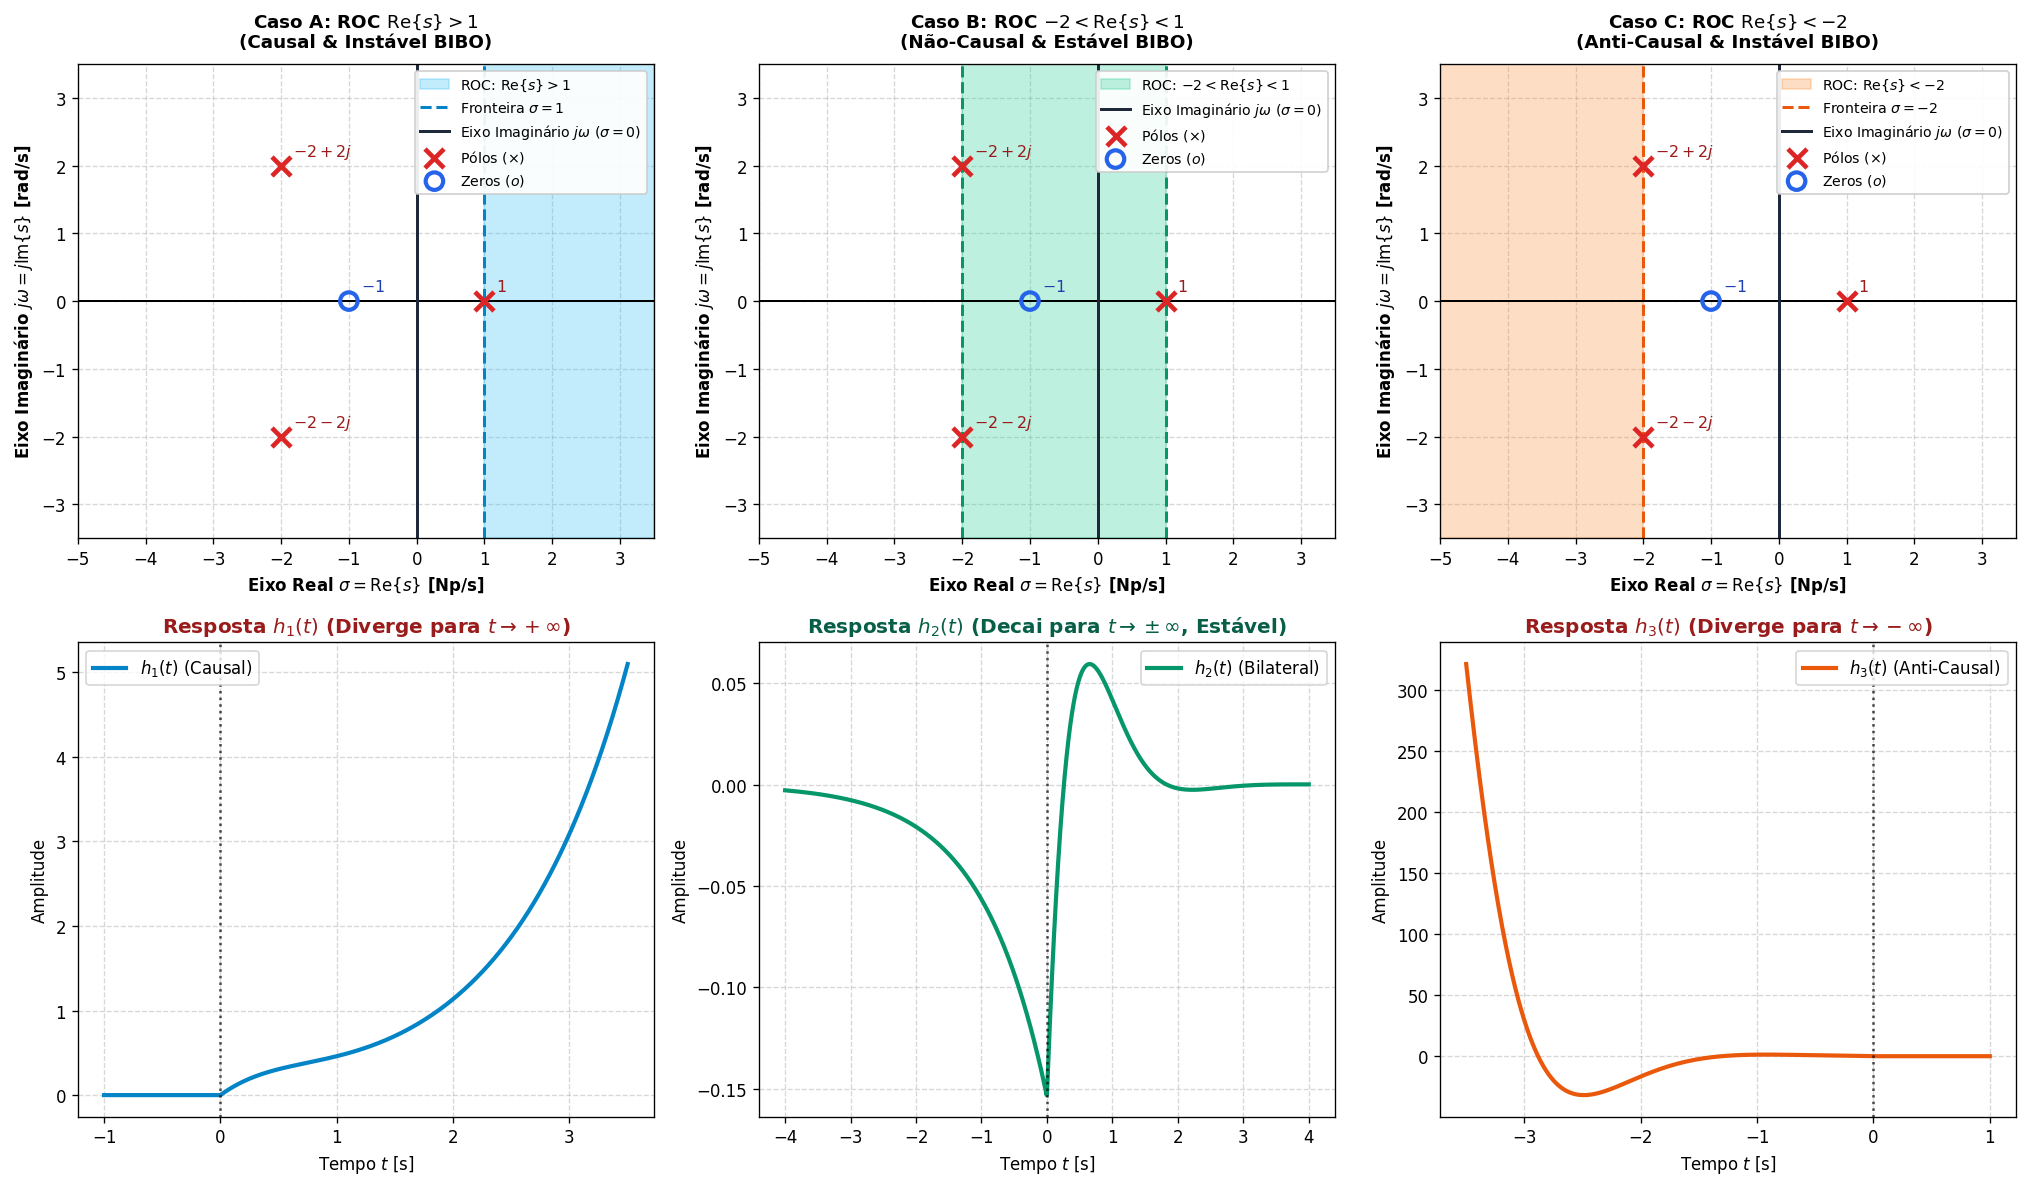

In [1]:
# ====================================================================
# CONFIGURAÇÃO DO AMBIENTE PYTHON & VISUALIZAÇÃO GRÁFICA DO ESTUDO TEÓRICO
# ====================================================================
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal
import sympy as sp
from sympy.integrals.transforms import inverse_laplace_transform

# Configurações estéticas e tipográficas para Engenharia Electrotécnica
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.5
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['axes.axisbelow'] = True

def plot_pole_zero_roc(zeros=None, poles=None, roc_type='right', roc_bounds=None,
                      title='Diagrama Zero-Polar e ROC no Plano-s',
                      xlim=(-5, 4), ylim=(-4, 4), ax=None):
    # Desenha o diagrama zero-polar com sombreamento profissional da ROC no plano-s.
    # zeros: lista de zeros complexos ou reais
    # poles: lista de pólos complexos ou reais
    # roc_type: 'right' (semiplano direito), 'left' (semiplano esquerdo), 'strip' (faixa vertical)
    # roc_bounds: tuplo/lista com os limites reais da ROC
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5), dpi=120)
    else:
        fig = ax.figure

    # Sombreamento da Região de Convergência (ROC)
    if roc_type == 'right' and roc_bounds is not None:
        ax.axvspan(roc_bounds[0], xlim[1], color='#38bdf8', alpha=0.30,
                   label=f'ROC: $\\mathrm{{Re}}\\{{s\\}} > {roc_bounds[0]}$')
        ax.axvline(roc_bounds[0], color='#0284c7', linestyle='--', linewidth=1.8,
                   label=f'Fronteira $\\sigma = {roc_bounds[0]}$')
    elif roc_type == 'left' and roc_bounds is not None:
        ax.axvspan(xlim[0], roc_bounds[0], color='#fb923c', alpha=0.30,
                   label=f'ROC: $\\mathrm{{Re}}\\{{s\\}} < {roc_bounds[0]}$')
        ax.axvline(roc_bounds[0], color='#ea580c', linestyle='--', linewidth=1.8,
                   label=f'Fronteira $\\sigma = {roc_bounds[0]}$')
    elif roc_type == 'strip' and roc_bounds is not None:
        ax.axvspan(roc_bounds[0], roc_bounds[1], color='#34d399', alpha=0.32,
                   label=f'ROC: ${roc_bounds[0]} < \\mathrm{{Re}}\\{{s\\}} < {roc_bounds[1]}$')
        ax.axvline(roc_bounds[0], color='#059669', linestyle='--', linewidth=1.8)
        ax.axvline(roc_bounds[1], color='#059669', linestyle='--', linewidth=1.8)

    # Eixos cartesianos no plano complexo
    ax.axhline(0, color='black', linewidth=1.2)
    ax.axvline(0, color='#1e293b', linewidth=1.8, linestyle='-', label='Eixo Imaginário $j\\omega$ ($\\sigma = 0$)')

    # Marcação de Pólos (x a vermelho)
    if poles is not None and len(poles) > 0:
        poles = np.array(poles, dtype=complex)
        ax.scatter(poles.real, poles.imag, marker='x', s=130, color='#dc2626',
                   linewidths=2.8, zorder=6, label='Pólos ($\\times$)')
        for p in poles:
            re_str = f"{p.real:.2g}" if abs(p.real) > 1e-4 else "0"
            im_str = f"{p.imag:+.2g}j" if abs(p.imag) > 1e-4 else ""
            coord_str = f"${re_str}{im_str}$".replace("+-", "-")
            ax.annotate(coord_str, (p.real, p.imag), textcoords="offset points",
                        xytext=(7, 6), fontsize=9.5, weight='bold', color='#991b1b')

    # Marcação de Zeros (o a azul)
    if zeros is not None and len(zeros) > 0:
        zeros = np.array(zeros, dtype=complex)
        ax.scatter(zeros.real, zeros.imag, marker='o', s=110, facecolors='none',
                   edgecolors='#2563eb', linewidths=2.5, zorder=6, label='Zeros ($o$)')
        for z in zeros:
            re_str = f"{z.real:.2g}" if abs(z.real) > 1e-4 else "0"
            im_str = f"{z.imag:+.2g}j" if abs(z.imag) > 1e-4 else ""
            coord_str = f"${re_str}{im_str}$".replace("+-", "-")
            ax.annotate(coord_str, (z.real, z.imag), textcoords="offset points",
                        xytext=(7, 6), fontsize=9.5, weight='bold', color='#1e40af')

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_xlabel('Eixo Real $\\sigma = \\mathrm{Re}\\{s\\}$ [Np/s]', fontweight='bold')
    ax.set_ylabel('Eixo Imaginário $j\\omega = j\\mathrm{Im}\\{s\\}$ [rad/s]', fontweight='bold')
    ax.set_title(title, fontsize=11, fontweight='bold', pad=10)
    ax.legend(loc='upper right', framealpha=0.92, fontsize=8.5)
    return fig, ax

print("Função gráfica 'plot_pole_zero_roc' configurada com sucesso!")

# ====================================================================
# SIMULAÇÃO DO ESTUDO DE CASO: POLOS [1, -2+2j, -2-2j], ZERO [-1]
# ====================================================================
zeros_case = [-1]
poles_case = [1, -2 + 2j, -2 - 2j]

# Criação de grelha 2x3: Linha 1 = Diagramas Zero-Polar; Linha 2 = Respostas Impulsionais h(t)
fig, axs = plt.subplots(2, 3, figsize=(17, 10), dpi=120)

# --- 1. CASO A: ROC Re{s} > 1 (Causal e Instável) ---
plot_pole_zero_roc(zeros=zeros_case, poles=poles_case, roc_type='right', roc_bounds=(1,),
                  title='Caso A: ROC $\\mathrm{Re}\\{s\\} > 1$\n(Causal & Instável BIBO)',
                  xlim=(-5, 3.5), ylim=(-3.5, 3.5), ax=axs[0, 0])

t_a = np.linspace(-1, 3.5, 1000)
h_a = np.where(t_a >= 0, (2/13)*np.exp(t_a) - (2/13)*np.exp(-2*t_a)*np.cos(2*t_a) + (7/26)*np.exp(-2*t_a)*np.sin(2*t_a), 0.0)
axs[1, 0].plot(t_a, h_a, color='#0284c7', linewidth=2.5, label='$h_1(t)$ (Causal)')
axs[1, 0].axvline(0, color='black', linestyle=':', alpha=0.7)
axs[1, 0].set_title('Resposta $h_1(t)$ (Diverge para $t \\to +\\infty$)', fontweight='bold', color='#991b1b')
axs[1, 0].set_xlabel('Tempo $t$ [s]')
axs[1, 0].set_ylabel('Amplitude')
axs[1, 0].legend(loc='upper left')

# --- 2. CASO B: ROC -2 < Re{s} < 1 (Não-Causal e Estável BIBO) ---
plot_pole_zero_roc(zeros=zeros_case, poles=poles_case, roc_type='strip', roc_bounds=(-2, 1),
                  title='Caso B: ROC $-2 < \\mathrm{Re}\\{s\\} < 1$\n(Não-Causal & Estável BIBO)',
                  xlim=(-5, 3.5), ylim=(-3.5, 3.5), ax=axs[0, 1])

t_b = np.linspace(-4, 4, 1000)
h_b_anti = np.where(t_b < 0, -(2/13)*np.exp(t_b), 0.0)
h_b_caus = np.where(t_b >= 0, -(2/13)*np.exp(-2*t_b)*np.cos(2*t_b) + (7/26)*np.exp(-2*t_b)*np.sin(2*t_b), 0.0)
h_b = h_b_anti + h_b_caus
axs[1, 1].plot(t_b, h_b, color='#059669', linewidth=2.5, label='$h_2(t)$ (Bilateral)')
axs[1, 1].axvline(0, color='black', linestyle=':', alpha=0.7)
axs[1, 1].set_title('Resposta $h_2(t)$ (Decai para $t \\to \\pm\\infty$, Estável)', fontweight='bold', color='#065f46')
axs[1, 1].set_xlabel('Tempo $t$ [s]')
axs[1, 1].set_ylabel('Amplitude')
axs[1, 1].legend(loc='upper right')

# --- 3. CASO C: ROC Re{s} < -2 (Anti-Causal e Instável) ---
plot_pole_zero_roc(zeros=zeros_case, poles=poles_case, roc_type='left', roc_bounds=(-2,),
                  title='Caso C: ROC $\\mathrm{Re}\\{s\\} < -2$\n(Anti-Causal & Instável BIBO)',
                  xlim=(-5, 3.5), ylim=(-3.5, 3.5), ax=axs[0, 2])

t_c = np.linspace(-3.5, 1, 1000)
h_c = np.where(t_c < 0, -(2/13)*np.exp(t_c) + (2/13)*np.exp(-2*t_c)*np.cos(2*t_c) - (7/26)*np.exp(-2*t_c)*np.sin(2*t_c), 0.0)
axs[1, 2].plot(t_c, h_c, color='#ea580c', linewidth=2.5, label='$h_3(t)$ (Anti-Causal)')
axs[1, 2].axvline(0, color='black', linestyle=':', alpha=0.7)
axs[1, 2].set_title('Resposta $h_3(t)$ (Diverge para $t \\to -\\infty$)', fontweight='bold', color='#991b1b')
axs[1, 2].set_xlabel('Tempo $t$ [s]')
axs[1, 2].set_ylabel('Amplitude')
axs[1, 2].legend(loc='upper right')

plt.tight_layout()
plt.show()

# Verificação Simbólica no SymPy
s_sym, t_sym = sp.symbols('s t', complex=True)
H_sym = (s_sym + 1) / ((s_sym - 1) * (s_sym**2 + 4*s_sym + 8))
apart_sym = sp.apart(H_sym, s_sym)

print("="*80)
print("VERIFICAÇÃO SIMBÓLICA COM SYMPY — ESTUDO DE CASO:")
print("="*80)
print(f"H(s) = {H_sym}")
print(f"Decomposição em Frações Parciais: H(s) = {apart_sym}")
print("Pólos: [1, -2 + 2j, -2 - 2j]")
print("Zeros: [-1]")
print("Resíduo no pólo s = 1:", sp.limit((s_sym - 1)*H_sym, s_sym, 1))
print("="*80)


## Exercício 20

### Análise de Circuito RLC Série com Condições Iniciais Não Nulas

> **Enunciado Oficial da Folha Prática TP05b:**  
> Considere um circuito RLC série, caraterizado pelas seguintes relações:  
> $$v_S(t) = v_R(t) + v_L(t) + v_C(t)$$, sendo:  
> * $v_R(t) = R \cdot i(t)$  
> * $v_L(t) = L \cdot \frac{di(t)}{dt}$  
> * $v_C(t) = \frac{1}{C} \int_{-\infty}^{t} i(\tau) \, d\tau$  
> *(Nota pedagógica: retifica-se o limite superior do integral para $t$, respeitando a causalidade física do condensador).*
>
> **a)** Obtenha uma equação diferencial linear de coeficientes constantes (EDLCC) que descreva o circuito.  
> **b)** Determine a função de transferência do circuito, $H(s) = \frac{V_C(s)}{V_S(s)}$.  
> **c)** Assuma agora que $R = 6\,\Omega$, $L = 0.5\text{ H}$ e $C = 0.1\text{ F}$. Sabendo que em $t = 0$ a corrente que percorre a bobine é nula ($i(0^-) = 0\text{ A}$) e a tensão aos terminais do condensador é $12\text{ V}$ ($v_C(0^-) = 12\text{ V}$), calcule para $t > 0^-$ a saída do sistema, $v_o(t) = v_C(t)$, quando à sua entrada é aplicado um sinal $v_S(t) = 10\text{ V}$ para $t > 0^-$.

---

### Resolução da Alínea 20. a) — Dedução da EDLCC do Circuito

#### 1. Aplicação da Lei das Tensões de Kirchhoff (LKT / 2.ª Lei)
Percorrendo a malha fechada única do circuito RLC série:
$$v_S(t) = v_R(t) + v_L(t) + v_C(t)$$

#### 2. Relações Constitutivas em Função da Tensão no Condensador $v_C(t)$
A saída de interesse do sistema é a tensão aos terminais do condensador, $v_C(t)$. Exprimem-se todas as tensões e correntes da malha em função direta de $v_C(t)$ e das suas derivadas:
1. **Condensador $C$**:
   A relação integral entre tensão e corrente é:
   $$v_C(t) = \frac{1}{C} \int_{-\infty}^t i(\tau) \, d\tau$$
   Diferenciando ambos os membros em ordem ao tempo pelo Teorema Fundamental do Cálculo:
   $$\frac{d v_C(t)}{dt} = \frac{1}{C} i(t) \iff \boxed{i(t) = C \frac{d v_C(t)}{dt}}$$
2. **Resistência $R$ (Lei de Ohm)**:
   Substituindo a corrente $i(t)$:
   $$\boxed{v_R(t) = R \cdot i(t) = R C \frac{d v_C(t)}{dt}}$$
3. **Bobina de Indutância $L$ (Lei de Faraday-Lenz)**:
   Diferenciando a corrente $i(t)$ em ordem ao tempo:
   $$\frac{d i(t)}{dt} = \frac{d}{dt}\left[ C \frac{d v_C(t)}{dt} \right] = C \frac{d^2 v_C(t)}{dt^2}$$
   Substituindo na tensão da bobina:
   $$\boxed{v_L(t) = L \frac{d i(t)}{dt} = L C \frac{d^2 v_C(t)}{dt^2}}$$

#### 3. Formulação da Equação Diferencial da Malha
Substituindo as expressões de $v_R(t)$, $v_L(t)$ e $v_C(t)$ na equação da malha:
$$v_S(t) = L C \frac{d^2 v_C(t)}{dt^2} + R C \frac{d v_C(t)}{dt} + v_C(t)$$

Reordenando na forma canónica clássica:
$$\boxed{L C \frac{d^2 v_C(t)}{dt^2} + R C \frac{d v_C(t)}{dt} + v_C(t) = v_S(t)}$$

Dividindo todos os coeficientes por $L C$, obtém-se a forma normalizada de 2.ª ordem com coeficiente unitário na derivada de mais alta ordem:
$$\boxed{\frac{d^2 v_C(t)}{dt^2} + \frac{R}{L} \frac{d v_C(t)}{dt} + \frac{1}{LC} v_C(t) = \frac{1}{LC} v_S(t)}$$


### Resolução da Alínea 20. b) — Função de Transferência $H(s) = \frac{V_C(s)}{V_S(s)}$

A determinação da Função de Transferência pode ser efetuada através de duas abordagens conceptuais equivalentes em Engenharia Electrotécnica:

---

#### Método 1: A Partir da EDLCC no Domínio do Tempo (com C.I. Nulas)
Por definição de **Função de Transferência** de um sistema LIT, assume-se que o circuito parte do repouso absoluto com todas as condições iniciais estritamente nulas:
$$v_C(0^-) = 0 \text{ V}, \quad v_C'(0^-) = \left. \frac{dv_C}{dt} \right|_{t=0^-} = \frac{i(0^-)}{C} = 0 \text{ V/s}$$

Aplicando a propriedade da diferenciação no tempo com condições iniciais nulas ($\mathcal{L}\left\{\frac{d^n x}{dt^n}\right\} = s^n X(s)$) à EDLCC obtida na alínea a):
$$\mathcal{L}\left\{ LC \frac{d^2 v_C(t)}{dt^2} + RC \frac{dv_C(t)}{dt} + v_C(t) \right\} = \mathcal{L}\{v_S(t)\}$$
$$LC s^2 V_C(s) + RC s V_C(s) + V_C(s) = V_S(s) \iff (LC s^2 + RC s + 1) V_C(s) = V_S(s)$$

Isolando o quociente $\frac{V_C(s)}{V_S(s)}$:
$$\boxed{H(s) = \frac{V_C(s)}{V_S(s)} = \frac{1}{LC s^2 + RC s + 1} = \frac{\frac{1}{LC}}{s^2 + \frac{R}{L} s + \frac{1}{LC}}}$$

---

#### Método 2: Passagem Direta da Equação no Tempo para a Representação de Laplace (Impedâncias Operacionais & Divisor de Tensão)
Como alternativa prática direta em Teoria dos Circuitos, podemos transitar diretamente da relação integro-diferencial da malha no tempo para a sua representação algébrica no domínio-$s$.

Partindo da Lei das Tensões de Kirchhoff no tempo:
$$v_S(t) = v_R(t) + v_L(t) + v_C(t) = R \cdot i(t) + L \frac{di(t)}{dt} + \frac{1}{C}\int_{-\infty}^t i(\tau) \, d\tau$$

Sob condições iniciais nulas, a transformada de Laplace de cada parcela corresponde diretamente à sua impedância operacional multiplicada pela corrente $I(s)$:
* Resistência: $\mathcal{L}\{v_R(t)\} = R \cdot I(s) \quad \implies Z_R(s) = R$
* Bobina: $\mathcal{L}\left\{L \frac{di(t)}{dt}\right\} = s L \cdot I(s) \quad \implies Z_L(s) = sL$
* Condensador: $\mathcal{L}\left\{\frac{1}{C}\int_{-\infty}^t i(\tau) d\tau\right\} = \frac{1}{sC} \cdot I(s) \quad \implies Z_C(s) = \frac{1}{sC}$

A equação da malha no domínio da frequência complexa $s$ escreve-se imediatamente:
$$\boxed{V_S(s) = R \cdot I(s) + s L \cdot I(s) + \frac{1}{sC} \cdot I(s) = \left( R + s L + \frac{1}{sC} \right) I(s)}$$

A impedância total equivalente da malha série é $Z_{\text{eq}}(s) = R + s L + \frac{1}{sC}$. Como a saída é a tensão no condensador:
$$V_C(s) = Z_C(s) \cdot I(s) = \frac{1}{sC} \cdot I(s) \iff I(s) = s C \cdot V_C(s)$$

Substituindo $I(s)$ na equação da malha:
$$V_S(s) = \left( R + s L + \frac{1}{sC} \right) \cdot [s C V_C(s)] = \left( L C s^2 + R C s + 1 \right) V_C(s)$$

Obtém-se a Função de Transferência sob a forma canónica de um **divisor de tensão generalizado no plano-$s$**:
$$\boxed{H(s) = \frac{V_C(s)}{V_S(s)} = \frac{Z_C(s)}{Z_{\text{eq}}(s)} = \frac{\frac{1}{sC}}{R + s L + \frac{1}{sC}} = \frac{1}{LC s^2 + RC s + 1}}$$

---

#### Parâmetros Canónicos do Sistema de Segunda Ordem:
Comparando com a forma padrão $H(s) = \frac{K \omega_n^2}{s^2 + 2\zeta\omega_n s + \omega_n^2}$:
* **Ganho estático DC ($K$)**: $K = H(0) = 1$ (em regime estacionário contínuo, o condensador é um circuito aberto).
* **Frequência angular natural não amortecida ($\omega_n$)**: $\omega_n = \frac{1}{\sqrt{LC}}$
* **Fator de amortecimento ($\zeta$)**: $\zeta = \frac{R}{2}\sqrt{\frac{C}{L}}$
* **Região de Convergência (ROC)**: Por ser um circuito físico realizável e estritamente causal:
  $$\text{ROC}: \mathrm{Re}\{s\} > \max(\mathrm{Re}\{p_1\}, \mathrm{Re}\{p_2\})$$


### Resolução da Alínea 20. c) — Resposta Completa $v_o(t) = v_C(t)$ para $t > 0^-$ com Condições Iniciais

#### 1. Dados Numéricos e Parâmetros do Circuito
* Resistência: $R = 6\,\Omega$
* Indutância: $L = 0.5\text{ H}$
* Capacidade: $C = 0.1\text{ F}$
* Condições iniciais em $t = 0^-$:
  * Corrente na bobina: $i(0^-) = 0\text{ A}$
  * Tensão no condensador: $v_C(0^-) = 12\text{ V}$
  * Derivada inicial da tensão no condensador:
    $$v_C'(0^-) = \left. \frac{dv_C}{dt} \right|_{t=0^-} = \frac{i(0^-)}{C} = \frac{0}{0.1} = 0\text{ V/s}$$
* Excitação externa aplicada:
  $$v_S(t) = 10\text{ V para } t > 0^- \implies v_S(t) = 10 u(t) \iff V_S(s) = \frac{10}{s}, \quad \mathrm{Re}\{s\} > 0$$

#### 2. Cálculo dos Coeficientes e Pólos do Circuito
* $LC = 0.5 \times 0.1 = 0.05\text{ s}^2$
* $RC = 6 \times 0.1 = 0.6\text{ s}$
* $\frac{R}{L} = \frac{6}{0.5} = 12\text{ s}^{-1}, \quad \frac{1}{LC} = \frac{1}{0.05} = 20\text{ s}^{-2}$
* Frequência natural e fator de amortecimento:
  $$\omega_n = \sqrt{20} \approx 4.472\text{ rad/s}, \quad \zeta = \frac{12}{2\sqrt{20}} = \frac{6}{\sqrt{20}} \approx 1.3416 > 1 \implies \mathbf{Sobreamortecido}$$
* Pólos do circuito:
  $$s^2 + 12s + 20 = 0 \iff (s + 2)(s + 10) = 0 \implies \boxed{p_1 = -2\text{ rad/s}, \quad p_2 = -10\text{ rad/s}}$$
  Ambos os pólos são reais, distintos e estritamente negativos ($\mathrm{Re}\{p\} < 0$), correspondendo a dois modos aperiódicos estáveis com constantes de tempo $\tau_1 = 0.5\text{ s}$ e $\tau_2 = 0.1\text{ s}$.

---

#### Método 1: Resolução via EDLCC com Condições Iniciais

Aplicando a Transformada Unilateral $\mathcal{L}_+$ à EDLCC:
$$LC \left[ s^2 V_C(s) - s v_C(0^-) - v_C'(0^-) \right] + RC \left[ s V_C(s) - v_C(0^-) \right] + V_C(s) = V_S(s)$$
Substituindo $v_C(0^-) = 12\text{ V}$ e $v_C'(0^-) = 0\text{ V/s}$:
$$(LC s^2 + RC s + 1) V_C(s) = V_S(s) + 12(LC s + RC)$$
Multiplicando por $20$ (já que $\frac{1}{LC} = 20$):
$$(s^2 + 12s + 20) V_C(s) = 20 V_S(s) + 12(s + 12)$$
Substituindo $V_S(s) = \frac{10}{s}$:
$$V_C(s) = \underbrace{\frac{200}{s(s + 2)(s + 10)}}_{V_{C,\text{ZSR}}(s)} + \underbrace{\frac{12(s + 12)}{(s + 2)(s + 10)}}_{V_{C,\text{ZIR}}(s)}$$
Colocando sobre o mesmo denominador comum:
$$V_C(s) = \frac{200 + 12s(s + 12)}{s(s + 2)(s + 10)} = \frac{12s^2 + 144s + 200}{s(s + 2)(s + 10)}, \quad \mathrm{Re}\{s\} > 0$$

Decomposição em frações simples por resíduos de Heaviside:
$$V_C(s) = \frac{A}{s + 10} + \frac{B}{s + 2} + \frac{C}{s}$$
* $C = \left. \frac{12s^2 + 144s + 200}{(s + 2)(s + 10)} \right|_{s = 0} = \frac{200}{20} = 10$
* $B = \left. \frac{12s^2 + 144s + 200}{s(s + 10)} \right|_{s = -2} = \frac{48 - 288 + 200}{-16} = \frac{-40}{-16} = 2.5$
* $A = \left. \frac{12s^2 + 144s + 200}{s(s + 2)} \right|_{s = -10} = \frac{1200 - 1440 + 200}{80} = \frac{-40}{80} = -0.5$

$$\boxed{V_C(s) = \frac{10}{s} + \frac{2.5}{s + 2} - \frac{0.5}{s + 10}, \quad \mathrm{Re}\{s\} > 0}$$

Inversão para o domínio do tempo:
$$\boxed{v_C(t) = \left( 10 + 2.5 e^{-2t} - 0.5 e^{-10t} \right) u(t) \text{ [V]}}$$

---

#### Método 2: Resolução Direta no Domínio de Laplace (Circuito Equivalente em Impedâncias com Fontes de C.I.)

Transformando diretamente a malha com as fontes de condição inicial:
$$V_S(s) = R \cdot I(s) + \left[ s L \cdot I(s) - L \cdot i(0^-) \right] + \left[ \frac{1}{sC} \cdot I(s) + \frac{v_C(0^-)}{s} \right]$$
Agrupando os termos na corrente da malha $I(s)$:
$$\left( s L + R + \frac{1}{sC} \right) I(s) = V_S(s) + L \cdot i(0^-) - \frac{v_C(0^-)}{s}$$

Substituindo os valores numéricos ($R = 6$, $L = 0.5$, $C = 0.1$, $i(0^-) = 0$, $v_C(0^-) = 12$, $V_S(s) = \frac{10}{s}$):
$$\left( 0.5 s + 6 + \frac{10}{s} \right) I(s) = \frac{10}{s} - \frac{12}{s} = -\frac{2}{s}$$
Multiplicando por $s$:
$$(0.5 s^2 + 6 s + 10) I(s) = -2 \iff 0.5(s^2 + 12 s + 20) I(s) = -2 \implies \boxed{I(s) = \frac{-4}{s^2 + 12 s + 20}}$$

A tensão no condensador é calculada pela relação do ramo capacitivo com a sua fonte inicial:
$$V_C(s) = \frac{1}{sC} I(s) + \frac{v_C(0^-)}{s} = \frac{10}{s} \left( \frac{-4}{s^2 + 12 s + 20} \right) + \frac{12}{s}$$
$$V_C(s) = \frac{-40 + 12(s^2 + 12 s + 20)}{s(s^2 + 12 s + 20)} = \frac{12s^2 + 144s + 200}{s(s + 2)(s + 10)}, \quad \mathrm{Re}\{s\} > 0$$

Decomposição em frações simples por resíduos de Heaviside (exatamente com os mesmos termos):
$$\boxed{V_C(s) = \frac{10}{s} + \frac{2.5}{s + 2} - \frac{0.5}{s + 10}, \quad \mathrm{Re}\{s\} > 0}$$

Inversão para o domínio do tempo:
$$\boxed{v_C(t) = \left( 10 + 2.5 e^{-2t} - 0.5 e^{-10t} \right) u(t) \text{ [V]}}$$

> **Conclusão Metodológica:** Ambos os métodos conduzem à **mesma expressão matemática final**, quer no domínio da frequência complexa $s$, quer no domínio do tempo $t$.


### Análise e Decomposições Complementares para Engenharia Electrotécnica

Para uma compreensão aprofundada da dinâmica do circuito, analisemos as várias decomposições físicas da resposta obtida:

---

#### 1. Decomposição Causal: Resposta de Entrada Nula (ZIR) vs Resposta de Estado Nulo (ZSR)
* **Resposta de Entrada Nula ($v_{C,\text{ZIR}}(t)$, Resposta Livre)**:
  $$V_{C,\text{ZIR}}(s) = \frac{12(s + 12)}{(s + 2)(s + 10)} = \frac{15}{s + 2} - \frac{3}{s + 10}$$
  $$\boxed{v_{C,\text{ZIR}}(t) = \left( 15 e^{-2t} - 3 e^{-10t} \right) u(t) \text{ [V]}}$$
  *Em $t = 0^+$*: $v_{C,\text{ZIR}}(0^+) = 15 - 3 = 12\text{ V}$ (recupera a energia previamente acumulada).  
  *Em $t \to \infty$*: $v_{C,\text{ZIR}}(\infty) = 0\text{ V}$ (a energia dissipa-se integralmente na resistência $R$).
* **Resposta de Estado Nulo ($v_{C,\text{ZSR}}(t)$, Resposta Forçada)**:
  $$V_{C,\text{ZSR}}(s) = \frac{200}{s(s + 2)(s + 10)} = \frac{10}{s} - \frac{12.5}{s + 2} + \frac{2.5}{s + 10}$$
  $$\boxed{v_{C,\text{ZSR}}(t) = \left( 10 - 12.5 e^{-2t} + 2.5 e^{-10t} \right) u(t) \text{ [V]}}$$
  *Em $t = 0^+$*: $v_{C,\text{ZSR}}(0^+) = 10 - 12.5 + 2.5 = 0\text{ V}$ (partida do repouso).  
  *Em $t \to \infty$*: $v_{C,\text{ZSR}}(\infty) = 10\text{ V}$ (tensão final imposta pela fonte $V_S$).
* **Soma das Parcelas**:
  $$v_C(t) = v_{C,\text{ZIR}}(t) + v_{C,\text{ZSR}}(t) = (15 - 12.5)e^{-2t} + (-3 + 2.5)e^{-10t} + 10 = 10 + 2.5e^{-2t} - 0.5e^{-10t} \text{ [V]}$$

---

#### 2. Decomposição Temporal: Transitório vs Regime Permanente
* **Parcela Transitória**:
  $$v_{C,\text{tr}}(t) = \left( 2.5 e^{-2t} - 0.5 e^{-10t} \right) u(t) \text{ [V]}$$
  Amortecida pelos modos do circuito; anula-se na prática após $5 \tau_1 = 5 \times 0.5 = 2.5\text{ s}$.
* **Parcela de Regime Permanente**:
  $$v_{C,\text{rp}}(t) = 10 u(t) \text{ [V]}$$
  Valor constante que subsiste indefinidamente, ditado pela fonte contínua de excitação.

---

#### 3. Corrente na Malha e Tensões nos Restantes Componentes
* **Corrente na Malha $i(t)$**:
  $$i(t) = C \frac{dv_C(t)}{dt} = 0.1 \cdot \left[ -5 e^{-2t} + 5 e^{-10t} \right] = \boxed{0.5 \left( e^{-10t} - e^{-2t} \right) u(t) \text{ [A]}}$$
  *Ponto de pico de corrente*: Derivando $i(t)$ e igualando a zero:
  $$\frac{di}{dt} = 0 \implies -10 e^{-10t} + 2 e^{-2t} = 0 \iff e^{8t} = 5 \implies t_{\text{pico}} = \frac{\ln 5}{8} \approx 0.201\text{ s}$$
  $$i(t_{\text{pico}}) = 0.5(e^{-2.01} - e^{-0.402}) \approx -0.198\text{ A}$$
  O sinal negativo indica que a corrente inicial circula no sentido de descarga do condensador (que estava carregado a $12\text{ V}$ contra a fonte de $10\text{ V}$).
* **Tensão na Resistência $v_R(t)$**:
  $$\boxed{v_R(t) = R \cdot i(t) = 3(e^{-10t} - e^{-2t}) u(t) \text{ [V]}}$$
* **Tensão na Bobina $v_L(t)$**:
  $$\boxed{v_L(t) = L \frac{di(t)}{dt} = \left( -2.5 e^{-10t} + 0.5 e^{-2t} \right) u(t) \text{ [V]}}$$

---

#### 4. Verificação Físico-Matemática
1. **No instante $t = 0^+$**:
   * $v_C(0^+) = 10 + 2.5 - 0.5 = 12\text{ V} = v_C(0^-)$ (continuidade da tensão no condensador).
   * $i(0^+) = 0.5(1 - 1) = 0\text{ A} = i(0^-)$ (continuidade da corrente na bobina).
   * $v_R(0^+) = 0\text{ V}$ e $v_L(0^+) = -2.5 + 0.5 = -2\text{ V}$.
   * **Balanço da Lei das Tensões de Kirchhoff em $t = 0^+$**:
     $$v_R(0^+) + v_L(0^+) + v_C(0^+) = 0 - 2 + 12 = 10\text{ V} = v_S(0^+)$$
     A lei das malhas é cumprida perfeitamente! A bobina adquire instantaneamente $-2\text{ V}$ para compensar a sobretensão inicial do condensador.
2. **No regime estacionário ($t \to +\infty$)**:
   * $v_C(\infty) = 10\text{ V} = V_S$, $i(\infty) = 0\text{ A}$, $v_R(\infty) = 0\text{ V}$, $v_L(\infty) = 0\text{ V}$.
3. **Verificação pelos Teoremas dos Limites no Domínio-$s$**:
   * **TVI**: $\lim_{s \to \infty} s V_C(s) = \lim_{s \to \infty} \frac{12s^3 + 144s^2 + 200s}{s^3 + 12s^2 + 20s} = 12\text{ V} = v_C(0^+)$.
   * **TVF**: $\lim_{s \to 0} s V_C(s) = \lim_{s \to 0} \frac{12s^2 + 144s + 200}{s^2 + 12s + 20} = \frac{200}{20} = 10\text{ V} = v_C(\infty)$.


VERIFICAÇÃO ANALÍTICA E SIMBÓLICA (SYMPY) — EXERCÍCIO 20:
Função de Transferência H(s) = 20.0/(s**2 + 12.0*s + 20.0)
Método 1 (via EDLCC):       Vc(s) = 1.25/(0.5*s + 1.0) - 0.05/(0.1*s + 1.0) + 10.0/s
Método 2 (via Impedâncias): Vc(s) = 1.25/(0.5*s + 1.0) - 0.05/(0.1*s + 1.0) + 10.0/s
Expressões em Frações Simples São Idênticas? True
Resposta Temporal Método 1: vc(t) = 10.0 - 0.5*exp(-10.0*t) + 2.5*exp(-2.0*t)
Resposta Temporal Método 2: vc(t) = 10.0 - 0.5*exp(-10.0*t) + 2.5*exp(-2.0*t)
Respostas Temporais São Idênticas? True
Limites:
 - TVI (t -> 0+): lim s*Vc(s) = 12 V
 - TVF (t -> oo): lim s*Vc(s) = 10 V

Instante t [s] |  v_C(t) [V]  |   i(t) [A]   |  v_R(t) [V]  |  v_L(t) [V]  | LKT: Soma [V] 
 0+ (após 0-)  |   12.0000    |    0.0000    |    0.0000    |   -2.0000    |    10.0000    
    0.050      |   11.9588    |   -0.1492    |   -0.8949    |   -1.0639    |    10.0000    
    0.201      |   11.6050    |   -0.2675    |   -1.6050    |    0.0000    |    10.0000    
    0.500      

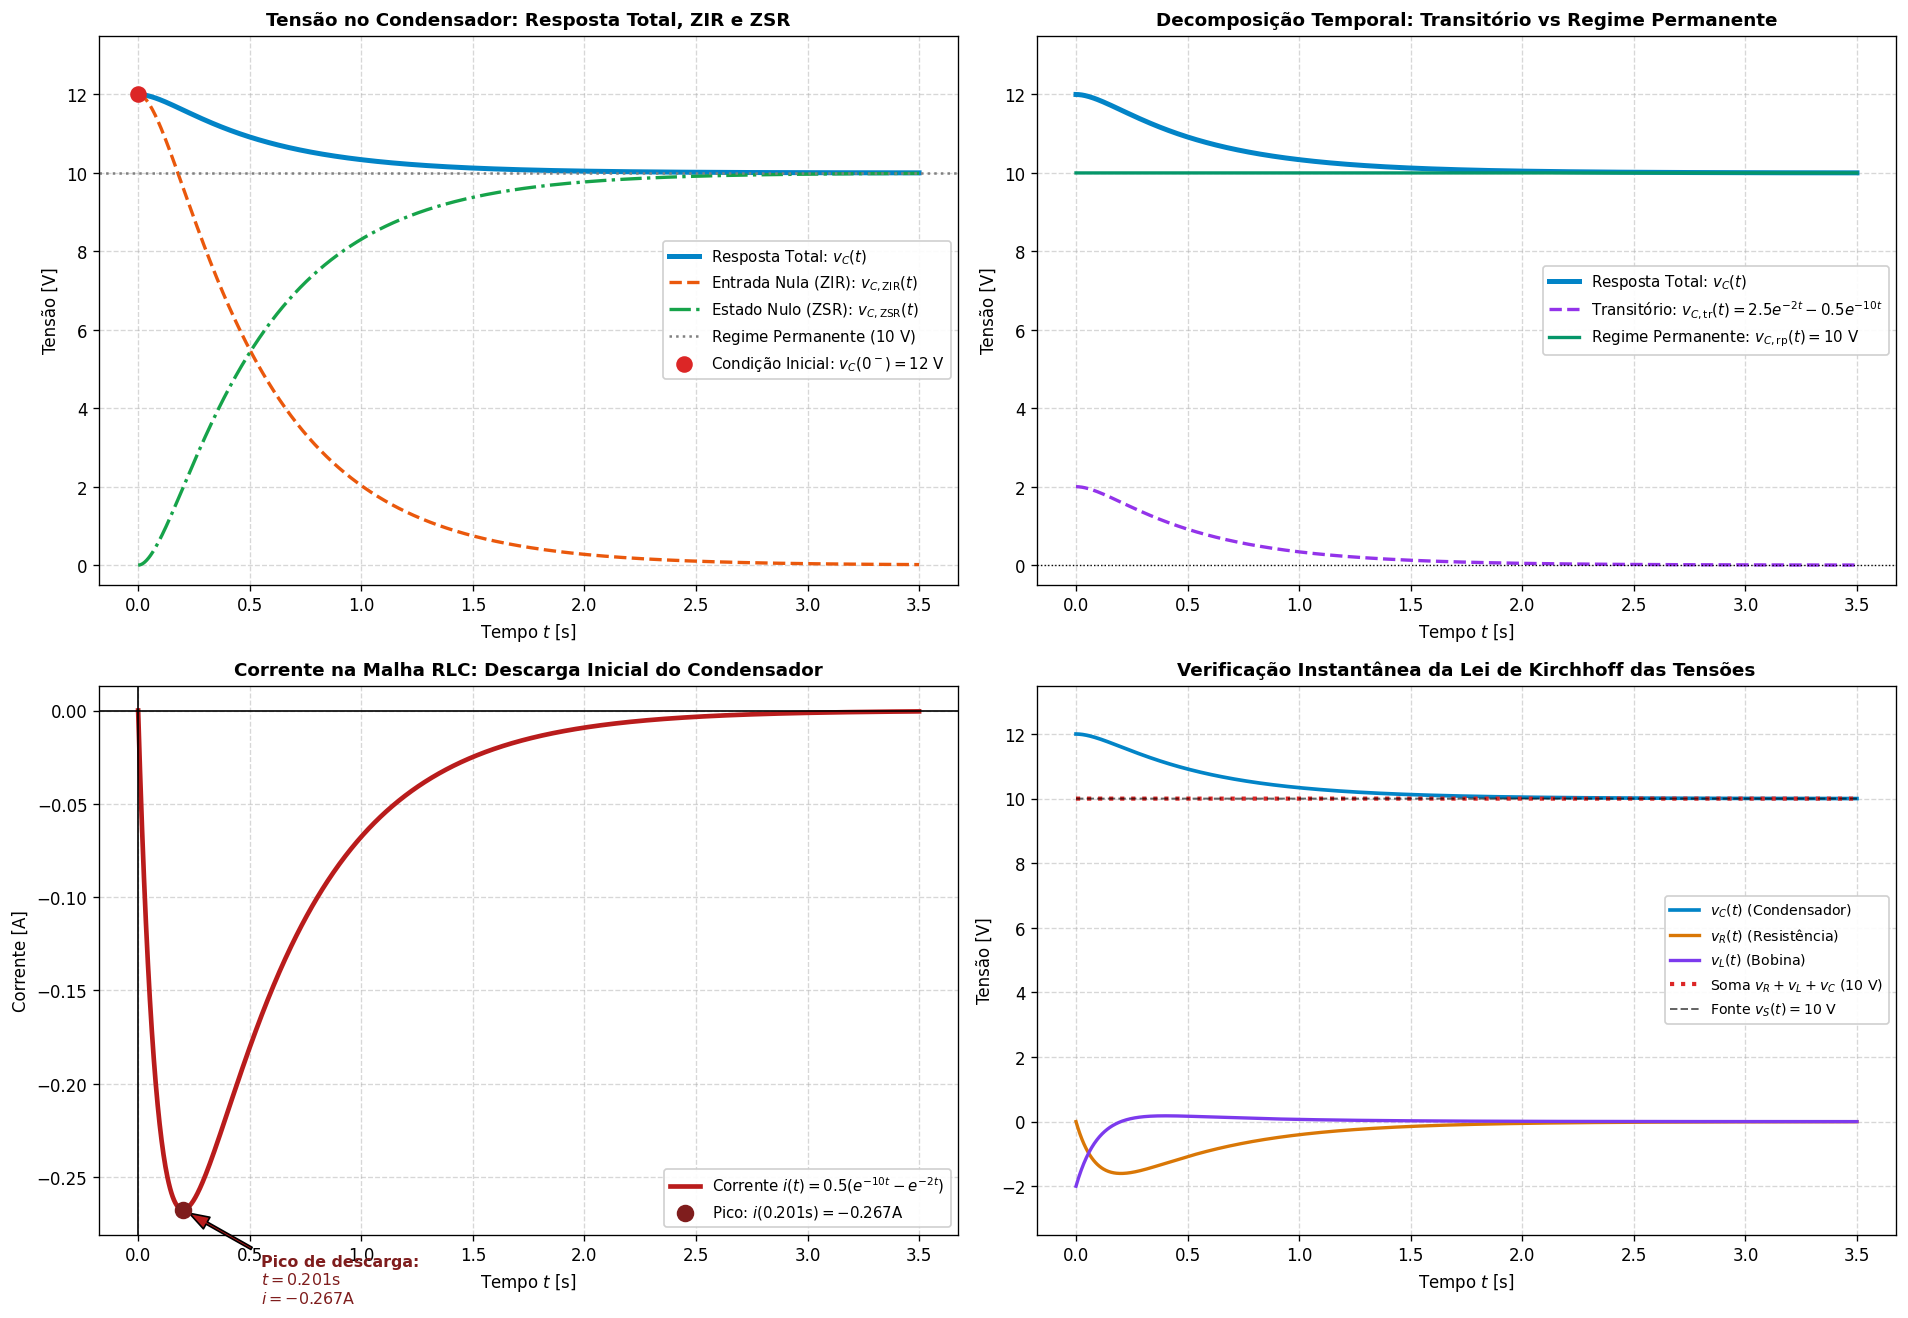

In [2]:
# ====================================================================
# SIMULAÇÃO COMPUTACIONAL & VALIDAÇÃO SIMBÓLICA — Exercício 20 (RLC Série)
# ====================================================================
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal
import sympy as sp
from sympy.integrals.transforms import inverse_laplace_transform

# --------------------------------------------------------------------
# 1. VERIFICAÇÃO SIMBÓLICA COMPLETA COM SYMPY (MÉTODO 1 vs MÉTODO 2)
# --------------------------------------------------------------------
s_sym = sp.Symbol('s', complex=True)
t_sym = sp.Symbol('t', real=True, positive=True)

# Parâmetros numéricos
R_val, L_val, C_val = 6.0, 0.5, 0.1
vc0_val, i0_val = 12.0, 0.0
vs0_val = 10.0

# Expressões simbólicas das transformadas
Vs_sym = vs0_val / s_sym
H_sym = (1 / (L_val * C_val)) / (s_sym**2 + (R_val / L_val) * s_sym + (1 / (L_val * C_val)))

# Resposta de entrada nula e de estado nulo (via EDLCC - Método 1)
V_zir_sym = vc0_val * (s_sym + (R_val / L_val)) / (s_sym**2 + (R_val / L_val) * s_sym + (1 / (L_val * C_val)))
V_zsr_sym = H_sym * Vs_sym
V_tot_m1 = sp.simplify(V_zir_sym + V_zsr_sym)

# Resposta pelo Método Direto de Impedâncias (Método 2)
Z_eq_sym = R_val + s_sym * L_val + 1 / (s_sym * C_val)
I_direct_sym = (Vs_sym + L_val * i0_val - vc0_val / s_sym) / Z_eq_sym
V_tot_m2 = sp.simplify(I_direct_sym / (s_sym * C_val) + vc0_val / s_sym)

# Decomposição em frações simples de ambos os métodos
V_apart_m1 = sp.apart(V_tot_m1, s_sym)
V_apart_m2 = sp.apart(V_tot_m2, s_sym)

# Inversão simbólica
vc_time_m1 = inverse_laplace_transform(V_apart_m1, s_sym, t_sym)
vc_time_m2 = inverse_laplace_transform(V_apart_m2, s_sym, t_sym)

print("="*85)
print("VERIFICAÇÃO ANALÍTICA E SIMBÓLICA (SYMPY) — EXERCÍCIO 20:")
print("="*85)
print(f"Função de Transferência H(s) = {sp.simplify(H_sym)}")
print(f"Método 1 (via EDLCC):       Vc(s) = {V_apart_m1}")
print(f"Método 2 (via Impedâncias): Vc(s) = {V_apart_m2}")
print(f"Expressões em Frações Simples São Idênticas? {V_apart_m1 == V_apart_m2}")
print(f"Resposta Temporal Método 1: vc(t) = {vc_time_m1}")
print(f"Resposta Temporal Método 2: vc(t) = {vc_time_m2}")
print(f"Respostas Temporais São Idênticas? {vc_time_m1 == vc_time_m2}")
print("Limites:")
print(f" - TVI (t -> 0+): lim s*Vc(s) = {sp.limit(s_sym * V_tot_m1, s_sym, sp.oo)} V")
print(f" - TVF (t -> oo): lim s*Vc(s) = {sp.limit(s_sym * V_tot_m1, s_sym, 0)} V")
print("="*85)

# --------------------------------------------------------------------
# 2. SIMULAÇÃO NUMÉRICA E VISUALIZAÇÃO GRÁFICA MULTIPAINEL
# --------------------------------------------------------------------
t = np.linspace(0, 3.5, 1200)

# Resposta Total e Decomposições
vc_tot = 10.0 + 2.5 * np.exp(-2.0 * t) - 0.5 * np.exp(-10.0 * t)
vc_zir = 15.0 * np.exp(-2.0 * t) - 3.0 * np.exp(-10.0 * t)
vc_zsr = 10.0 - 12.5 * np.exp(-2.0 * t) + 2.5 * np.exp(-10.0 * t)
vc_tr  = 2.5 * np.exp(-2.0 * t) - 0.5 * np.exp(-10.0 * t)
vc_rp  = np.full_like(t, 10.0)

# Corrente e Tensões nos restantes componentes
i_t  = 0.5 * (np.exp(-10.0 * t) - np.exp(-2.0 * t))
v_R  = 3.0 * (np.exp(-10.0 * t) - np.exp(-2.0 * t))
v_L  = -2.5 * np.exp(-10.0 * t) + 0.5 * np.exp(-2.0 * t)
v_S  = np.full_like(t, 10.0)
v_sum = v_R + v_L + vc_tot

# Criação da figura com grelha de 4 gráficos (2x2)
fig, axs = plt.subplots(2, 2, figsize=(16, 11), dpi=120)

# --- Subplot (0, 0): Tensão no Condensador e Decomposição ZIR / ZSR ---
axs[0, 0].plot(t, vc_tot, color='#0284c7', linewidth=3.0, label='Resposta Total: $v_C(t)$')
axs[0, 0].plot(t, vc_zir, color='#ea580c', linewidth=2.0, linestyle='--', label='Entrada Nula (ZIR): $v_{C,\\mathrm{ZIR}}(t)$')
axs[0, 0].plot(t, vc_zsr, color='#16a34a', linewidth=2.0, linestyle='-.', label='Estado Nulo (ZSR): $v_{C,\\mathrm{ZSR}}(t)$')
axs[0, 0].axhline(10.0, color='gray', linestyle=':', label='Regime Permanente ($10\\text{ V}$)')
axs[0, 0].scatter([0], [12.0], color='#dc2626', s=80, zorder=5, label='Condição Inicial: $v_C(0^-) = 12\\text{ V}$')
axs[0, 0].set_title('Tensão no Condensador: Resposta Total, ZIR e ZSR', fontweight='bold', fontsize=11)
axs[0, 0].set_xlabel('Tempo $t$ [s]')
axs[0, 0].set_ylabel('Tensão [V]')
axs[0, 0].set_ylim(-0.5, 13.5)
axs[0, 0].legend(loc='center right', framealpha=0.92, fontsize=9)

# --- Subplot (0, 1): Decomposição Transitório vs Regime Permanente ---
axs[0, 1].plot(t, vc_tot, color='#0284c7', linewidth=3.0, label='Resposta Total: $v_C(t)$')
axs[0, 1].plot(t, vc_tr, color='#9333ea', linewidth=2.0, linestyle='--', label='Transitório: $v_{C,\\mathrm{tr}}(t) = 2.5e^{-2t} - 0.5e^{-10t}$')
axs[0, 1].plot(t, vc_rp, color='#059669', linewidth=2.0, linestyle='-', label='Regime Permanente: $v_{C,\\mathrm{rp}}(t) = 10\\text{ V}$')
axs[0, 1].axhline(0, color='black', linewidth=0.8, linestyle=':')
axs[0, 1].set_title('Decomposição Temporal: Transitório vs Regime Permanente', fontweight='bold', fontsize=11)
axs[0, 1].set_xlabel('Tempo $t$ [s]')
axs[0, 1].set_ylabel('Tensão [V]')
axs[0, 1].set_ylim(-0.5, 13.5)
axs[0, 1].legend(loc='center right', framealpha=0.92, fontsize=9)

# --- Subplot (1, 0): Corrente na Malha i(t) e Ponto de Pico ---
t_peak = np.log(10.0 / 2.0) / (10.0 - 2.0)  # ln(5) / 8 ≈ 0.201 s
i_peak = 0.5 * (np.exp(-10.0 * t_peak) - np.exp(-2.0 * t_peak))

axs[1, 0].plot(t, i_t, color='#b91c1c', linewidth=2.8, label='Corrente $i(t) = 0.5(e^{-10t} - e^{-2t})$')
axs[1, 0].scatter([t_peak], [i_peak], color='#7f1d1d', s=90, zorder=6,
                  label=f'Pico: $i({t_peak:.3f}\\mathrm{{s}}) = {i_peak:.3f}\\mathrm{{ A}}$')
axs[1, 0].axhline(0, color='black', linewidth=1.0)
axs[1, 0].axvline(0, color='black', linewidth=1.0)
axs[1, 0].annotate(f'Pico de descarga:\n$t = {t_peak:.3f}\\mathrm{{ s}}$\n$i = {i_peak:.3f}\\mathrm{{ A}}$',
                   xy=(t_peak, i_peak), xytext=(t_peak + 0.35, i_peak - 0.05),
                   arrowprops=dict(facecolor='#b91c1c', shrink=0.08, width=1.5, headwidth=8),
                   fontsize=9.5, fontweight='bold', color='#7f1d1d')
axs[1, 0].set_title('Corrente na Malha RLC: Descarga Inicial do Condensador', fontweight='bold', fontsize=11)
axs[1, 0].set_xlabel('Tempo $t$ [s]')
axs[1, 0].set_ylabel('Corrente [A]')
axs[1, 0].legend(loc='lower right', framealpha=0.92, fontsize=9)

# --- Subplot (1, 1): Balanço de Tensões na Malha (Verificação da LKT) ---
axs[1, 1].plot(t, vc_tot, color='#0284c7', linewidth=2.2, label='$v_C(t)$ (Condensador)')
axs[1, 1].plot(t, v_R, color='#d97706', linewidth=2.0, label='$v_R(t)$ (Resistência)')
axs[1, 1].plot(t, v_L, color='#7c3aed', linewidth=2.0, label='$v_L(t)$ (Bobina)')
axs[1, 1].plot(t, v_sum, color='#dc2626', linewidth=2.5, linestyle=':', label='Soma $v_R + v_L + v_C$ ($10\\text{ V}$)')
axs[1, 1].plot(t, v_S, color='black', linewidth=1.2, linestyle='--', alpha=0.6, label='Fonte $v_S(t) = 10\\text{ V}$')
axs[1, 1].set_title('Verificação Instantânea da Lei de Kirchhoff das Tensões', fontweight='bold', fontsize=11)
axs[1, 1].set_xlabel('Tempo $t$ [s]')
axs[1, 1].set_ylabel('Tensão [V]')
axs[1, 1].set_ylim(-3.5, 13.5)
axs[1, 1].legend(loc='center right', framealpha=0.92, fontsize=8.5)

plt.tight_layout()
plt.show()

# --------------------------------------------------------------------
# 3. TABELA DE VERIFICAÇÃO NUMÉRICA NOS INSTANTES CHAVE
# --------------------------------------------------------------------
instants = [0.0, 0.05, t_peak, 0.5, 1.0, 2.0, 3.5]
print("\n" + "="*85)
print(f"{'Instante t [s]':^14} | {'v_C(t) [V]':^12} | {'i(t) [A]':^12} | {'v_R(t) [V]':^12} | {'v_L(t) [V]':^12} | {'LKT: Soma [V]':^14}")
print("="*85)
for ti in instants:
    vc_i = 10.0 + 2.5 * np.exp(-2.0 * ti) - 0.5 * np.exp(-10.0 * ti)
    i_i  = 0.5 * (np.exp(-10.0 * ti) - np.exp(-2.0 * ti))
    vr_i = 6.0 * i_i
    vl_i = -2.5 * np.exp(-10.0 * ti) + 0.5 * np.exp(-2.0 * ti)
    sum_i = vr_i + vl_i + vc_i
    label = f"{ti:.3f}" if ti != 0 else "0+ (após 0-)"
    print(f"{label:^14} | {vc_i:^12.4f} | {i_i:^12.4f} | {vr_i:^12.4f} | {vl_i:^12.4f} | {sum_i:^14.4f}")
print("="*85)


## 3. Quadro Síntese dos Resultados da Folha Prática TP05b

A tabela seguinte compila todos os resultados obtidos analiticamente para o circuito RLC série sob estudo:

| Propriedade / Grandeza | Expressão Matemática / Domínio-$s$ | Expressão Temporal ($t > 0^-$) | Significado Físico em Engenharia Electrotécnica |
| :--- | :--- | :--- | :--- |
| **EDLCC do Circuito** | $LC \ddot{v}_C + RC \dot{v}_C + v_C = v_S$ | $0.05 \ddot{v}_C + 0.6 \dot{v}_C + v_C = v_S$ | Balanço dinâmico de tensões na malha (2.ª Lei de Kirchhoff). |
| **Função de Transferência** | $H(s) = \frac{20}{s^2 + 12s + 20}$ | $h(t) = 2.5(e^{-2t} - e^{-10t})u(t)$ | Ganho unitário DC ($K=1$), pólos em $s = -2$ e $s = -10$. Sem zeros finitos. |
| **Amortecimento & Freq.** | $\omega_n = \sqrt{20} \approx 4.47\text{ rad/s}$, $\zeta \approx 1.34$ | Regime Sobreamortecido | Não oscilatório. Dois modos aperiódicos com $\tau_1 = 0.5\text{ s}$ e $\tau_2 = 0.1\text{ s}$. |
| **Resposta Entrada Nula (ZIR)** | $V_{C,\text{ZIR}}(s) = \frac{12s + 144}{s^2 + 12s + 20}$ | $v_{C,\text{ZIR}}(t) = 15e^{-2t} - 3e^{-10t}\text{ V}$ | Descarregamento da energia inicial do condensador ($12\text{ V} \to 0\text{ V}$). |
| **Resposta Estado Nulo (ZSR)** | $V_{C,\text{ZSR}}(s) = \frac{200}{s(s^2 + 12s + 20)}$ | $v_{C,\text{ZSR}}(t) = 10 - 12.5e^{-2t} + 2.5e^{-10t}\text{ V}$ | Resposta forçada pela fonte de $10\text{ V}$ partindo do repouso ($0\text{ V} \to 10\text{ V}$). |
| **Resposta Total $v_C(t)$** | $V_C(s) = \frac{10}{s} + \frac{2.5}{s+2} - \frac{0.5}{s+10}$ | $v_C(t) = 10 + 2.5e^{-2t} - 0.5e^{-10t}\text{ V}$ | Tensão de saída real: inicia em $12\text{ V}$ e estabiliza em $10\text{ V}$. |
| **Resposta Transitória** | $V_{C,\text{tr}}(s) = \frac{2.5}{s+2} - \frac{0.5}{s+10}$ | $v_{C,\text{tr}}(t) = 2.5e^{-2t} - 0.5e^{-10t}\text{ V}$ | Perturbação transitória que se extingue com o tempo ($t > 5\tau_1 = 2.5\text{ s}$). |
| **Regime Permanente** | $V_{C,\text{rp}}(s) = \frac{10}{s}$ | $v_{C,\text{rp}}(t) = 10\text{ V}$ | Estado estacionário DC forçado pela fonte externa de excitação. |
| **Corrente na Malha $i(t)$** | $I(s) = \frac{-4}{s^2 + 12s + 20}$ | $i(t) = 0.5(e^{-10t} - e^{-2t})\text{ A}$ | Corrente de descarga inicial; atinge pico de $-0.198\text{ A}$ em $t \approx 0.201\text{ s}$. |

---

### Síntese Universal: Diagrama Zero-Polar $\leftrightarrow$ ROC $\leftrightarrow$ Causalidade & Estabilidade

| Configuração da ROC no Plano-$s$ | Relação com os Pólos | Causalidade do Sistema | Estabilidade BIBO | Condição Crítica |
| :--- | :--- | :--- | :--- | :--- |
| **Semiplano Direito** | $\mathrm{Re}\{s\} > \max_k \mathrm{Re}\{p_k\}$ | **Causal** ($h(t) = 0, \forall t < 0$) | **Estável** se $\max \mathrm{Re}\{p_k\} < 0$ | Estável $\iff$ Todos os pólos no Semiplano Esquerdo (SPE). |
| **Faixa Vertical Central** | $\sigma_a < \mathrm{Re}\{s\} < \sigma_b$ | **Não-Causal (Bilateral)** | **Estável** se $\sigma_a < 0 < \sigma_b$ | Estável $\iff$ O eixo imaginário $j\omega$ está contido no interior da faixa. |
| **Semiplano Esquerdo** | $\mathrm{Re}\{s\} < \min_k \mathrm{Re}\{p_k\}$ | **Anti-Causal** ($h(t) = 0, \forall t > 0$) | **Instável** em geral | Estável apenas se $\min \mathrm{Re}\{p_k\} > 0$ (impossível se houver pólos no SPE). |

---

## 4. Notas pedagógicas:

1. **Atenção ao Instante $t = 0^-$ em Circuitos Dinâmicos**:
   Ao resolver circuitos excitados por degraus ou comutações, nunca assuma condições iniciais em $t = 0^+$ sem antes verificar a continuidade das variáveis de estado. A corrente na bobina $i_L(t)$ e a tensão no condensador $v_C(t)$ são grandezas contínuas:
   $$i_L(0^+) = i_L(0^-), \quad v_C(0^+) = v_C(0^-)$$
   No entanto, as tensões nas bobinas ($v_L$) e as correntes nos condensadores ($i_C$) podem sofrer saltos instantâneos e descontínuos em $t = 0^+$, como verificado no Exercício 20 ($v_L(0^+) = -2\text{ V}$ enquanto $v_L(0^-) = 0\text{ V}$).
2. **Utilize Sempre os Teoremas do Valor Inicial e Final como Teste de Sanidade**:
   Após obter a decomposição em frações simples no domínio-$s$, aplique imediatamente:
   - TVI: $\lim_{s \to \infty} s X(s) \stackrel{?}{=} x(0^+)$
   - TVF: $\lim_{s \to 0} s X(s) \stackrel{?}{=} x(\infty)$
   Estes dois testes levam menos de 30 segundos a calcular e evitam a grande maioria dos erros algébricos em exames e relatórios técnicos.
3. **Não Confunda Decomposição ZIR/ZSR com Transitório/Permanente**:
   - A decomposição **ZIR / ZSR** baseia-se na **origem física da excitação** (energia prévia vs fonte externa).
   - A decomposição **Transitório / Permanente** baseia-se na **evolução temporal assintótica** ($t \to \infty$).
   - A resposta de estado nulo ($v_{C,\text{ZSR}}$) contém parcelas transitórias e parcelas de regime permanente!
4. **Dominar a Dualidade: EDLCC vs Método Direto de Impedâncias**:
   Em exercícios com alíneas independentes, saiba alternar com agilidade entre a formulação clássica por equações diferenciais no tempo e o método direto de impedâncias e fontes de condição inicial em $s$. Ambos conduzem exatamente à mesma expressão final e servem de confirmação recíproca incontestável.
